In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("EDA notebook started successfully.")

EDA notebook started successfully.


In [2]:
import os

EDA_DIR = "../data/processed/eda"

overview = pd.read_csv(
    os.path.join(EDA_DIR, "transaction_overview.csv")
)

channel_df = pd.read_csv(
    os.path.join(EDA_DIR, "sales_channel_distribution.csv")
)

monthly_df = pd.read_csv(
    os.path.join(EDA_DIR, "monthly_transactions.csv")
)

top_articles_df = pd.read_csv(
    os.path.join(EDA_DIR, "top_articles.csv")
)

top_customers_df = pd.read_csv(
    os.path.join(EDA_DIR, "top_customers.csv")
)

print("EDA datasets loaded successfully.")

EDA datasets loaded successfully.


In [3]:
overview


,transaction_count,unique_customers,unique_articles,first_transaction_date,last_transaction_date,minimum_price,maximum_price,average_price
0,31788324,1362281,104547,2018-09-20,2020-09-22,0.000017,0.591525,0.027829


In [4]:
print("===== H&M DATASET OVERVIEW =====")
print(f"Total transactions : {overview.loc[0, 'transaction_count']:,}")
print(f"Unique customers   : {overview.loc[0, 'unique_customers']:,}")
print(f"Unique articles    : {overview.loc[0, 'unique_articles']:,}")
print(f"First transaction  : {overview.loc[0, 'first_transaction_date']}")
print(f"Last transaction   : {overview.loc[0, 'last_transaction_date']}")
print(f"Minimum price      : {overview.loc[0, 'minimum_price']:.6f}")
print(f"Maximum price      : {overview.loc[0, 'maximum_price']:.6f}")
print(f"Average price      : {overview.loc[0, 'average_price']:.6f}")

===== H&M DATASET OVERVIEW =====
Total transactions : 31,788,324
Unique customers   : 1,362,281
Unique articles    : 104,547
First transaction  : 2018-09-20
Last transaction   : 2020-09-22
Minimum price      : 0.000017
Maximum price      : 0.591525
Average price      : 0.027829


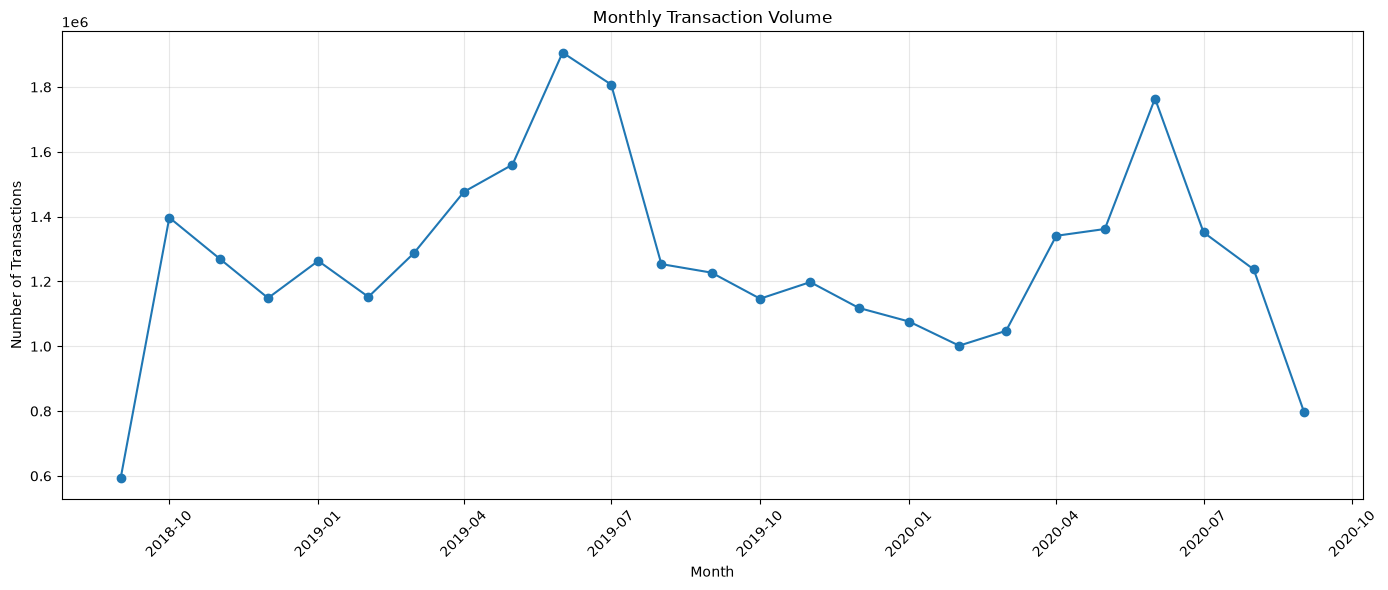

In [5]:
monthly_df["month"] = pd.to_datetime(monthly_df["month"])

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_df["month"],
    monthly_df["count"],
    marker="o"
)

plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [6]:
channel_df

,sales_channel_id,count
0,1,9408462
1,2,22379862


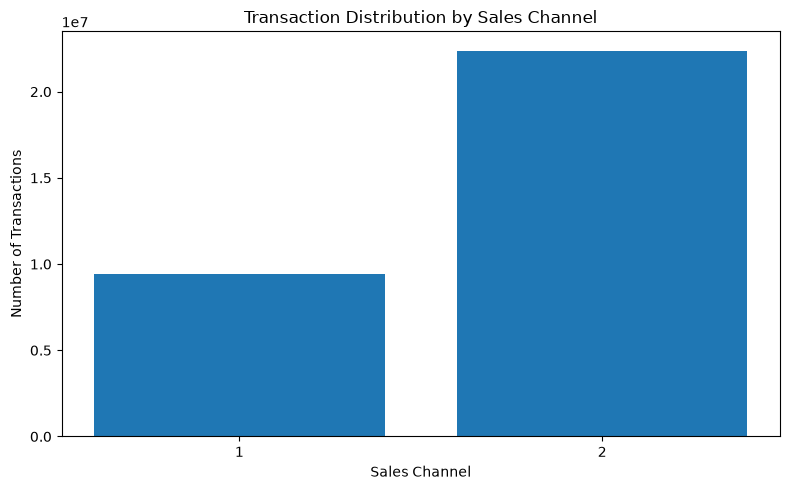

In [7]:
plt.figure(figsize=(8, 5))

plt.bar(
    channel_df["sales_channel_id"].astype(str),
    channel_df["count"]
)

plt.title("Transaction Distribution by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [8]:
channel_df["percentage"] = (
    channel_df["count"] / channel_df["count"].sum() * 100
)

channel_df

,sales_channel_id,count,percentage
0,1,9408462,29.597226
1,2,22379862,70.402774


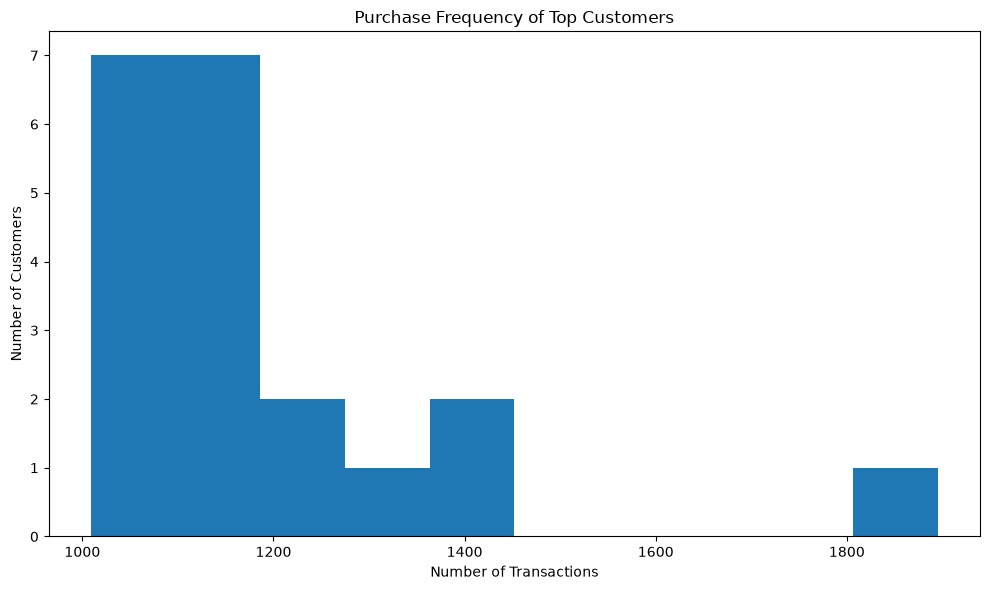

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(
    top_customers_df["count"],
    bins=10
)

plt.title("Purchase Frequency of Top Customers")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [10]:
top_customers_df.head(10)

,customer_id,count
0,be1981ab818cf4ef6765b2ecaea7a2cbf14ccd6e8a7ee9...,1895
1,b4db5e5259234574edfff958e170fe3a5e13b6f146752c...,1441
2,49beaacac0c7801c2ce2d189efe525fe80b5d37e46ed05...,1364
3,a65f77281a528bf5c1e9f270141d601d116e1df33bf9df...,1361
4,cd04ec2726dd58a8c753e0d6423e57716fd9ebcf2f14ed...,1237
5,55d15396193dfd45836af3a6269a079efea339e875eff4...,1208
6,c140410d72a41ee5e2e3ba3d7f5a860f337f1b5e41c27c...,1170
7,8df45859ccd71ef1e48e2ee9d1c65d5728c31c46ae957d...,1169
8,03d0011487606c37c1b1ed147fc72f285a50c05f00b971...,1157
9,6cc121e5cc202d2bf344ffe795002bdbf87178054bcda2...,1143


In [11]:
top_articles_df.head(20)

,article_id,count
0,706016001,50287
1,706016002,35043
2,372860001,31718
3,610776002,30199
4,759871002,26329
5,464297007,25025
6,372860002,24458
7,610776001,22451
8,399223001,22236
9,706016003,21241


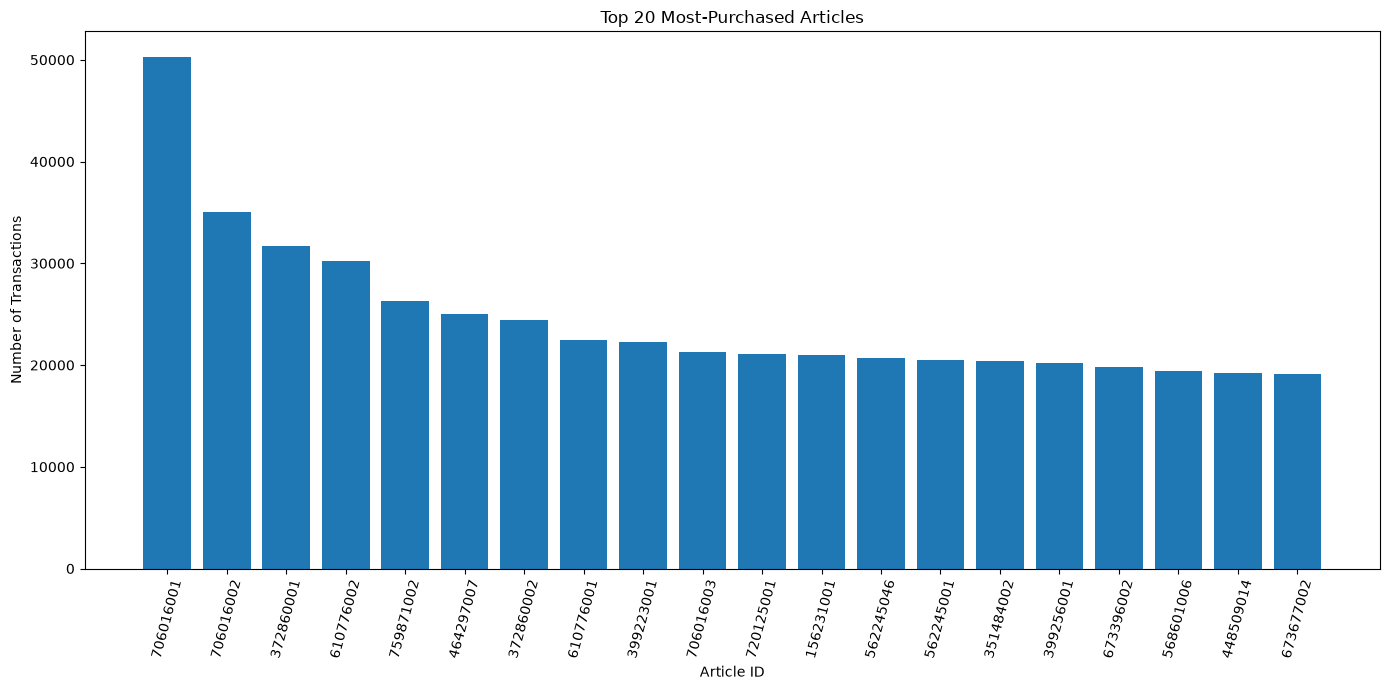

In [12]:
plt.figure(figsize=(14, 7))

plt.bar(
    top_articles_df["article_id"].astype(str),
    top_articles_df["count"]
)

plt.title("Top 20 Most-Purchased Articles")
plt.xlabel("Article ID")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

In [13]:
print("Top article transactions:")
print(f"Maximum: {top_articles_df['count'].max():,}")
print(f"Minimum among top 20: {top_articles_df['count'].min():,}")
print(f"Average among top 20: {top_articles_df['count'].mean():,.0f}")

Top article transactions:
Maximum: 50,287
Minimum among top 20: 19,143
Average among top 20: 24,524


In [14]:
customers_path = r"C:\Users\SASHANK VARMA K\recommendation-engine-ml-backup\data\raw\customers.csv"

customers_df = pd.read_csv(
    customers_path,
    usecols=[
        "customer_id",
        "FN",
        "Active",
        "club_member_status",
        "fashion_news_frequency",
        "age"
    ]
)

print("Customers loaded:", customers_df.shape)
customers_df.head()

Customers loaded: (1371980, 6)


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0


In [15]:
customer_missing = (
    customers_df.isna()
    .sum()
    .sort_values(ascending=False)
)

customer_missing

Active                    907576
FN                        895050
fashion_news_frequency     16011
age                        15861
club_member_status          6062
customer_id                    0
dtype: int64

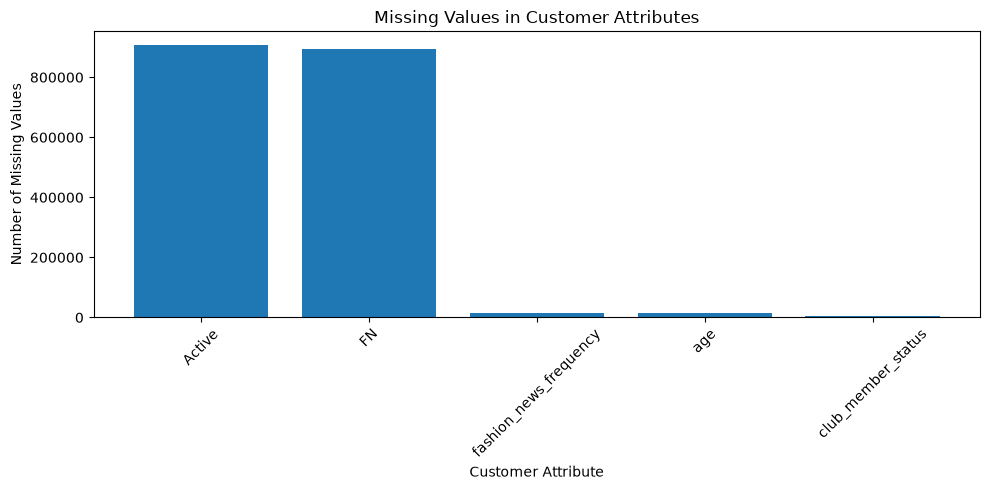

In [16]:
missing = customer_missing[customer_missing > 0]

plt.figure(figsize=(10, 5))

plt.bar(
    missing.index,
    missing.values
)

plt.title("Missing Values in Customer Attributes")
plt.xlabel("Customer Attribute")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
customer_missing_pct = (
    customer_missing / len(customers_df) * 100
).round(2)

customer_missing_pct


Active                    66.15
FN                        65.24
fashion_news_frequency     1.17
age                        1.16
club_member_status         0.44
customer_id                0.00
dtype: float64

In [18]:
print("===== CUSTOMER AGE STATISTICS =====")

print(f"Minimum age : {customers_df['age'].min()}")
print(f"Maximum age : {customers_df['age'].max()}")
print(f"Average age : {customers_df['age'].mean():.2f}")
print(f"Median age  : {customers_df['age'].median():.2f}")

===== CUSTOMER AGE STATISTICS =====
Minimum age : 16.0
Maximum age : 99.0
Average age : 36.39
Median age  : 32.00


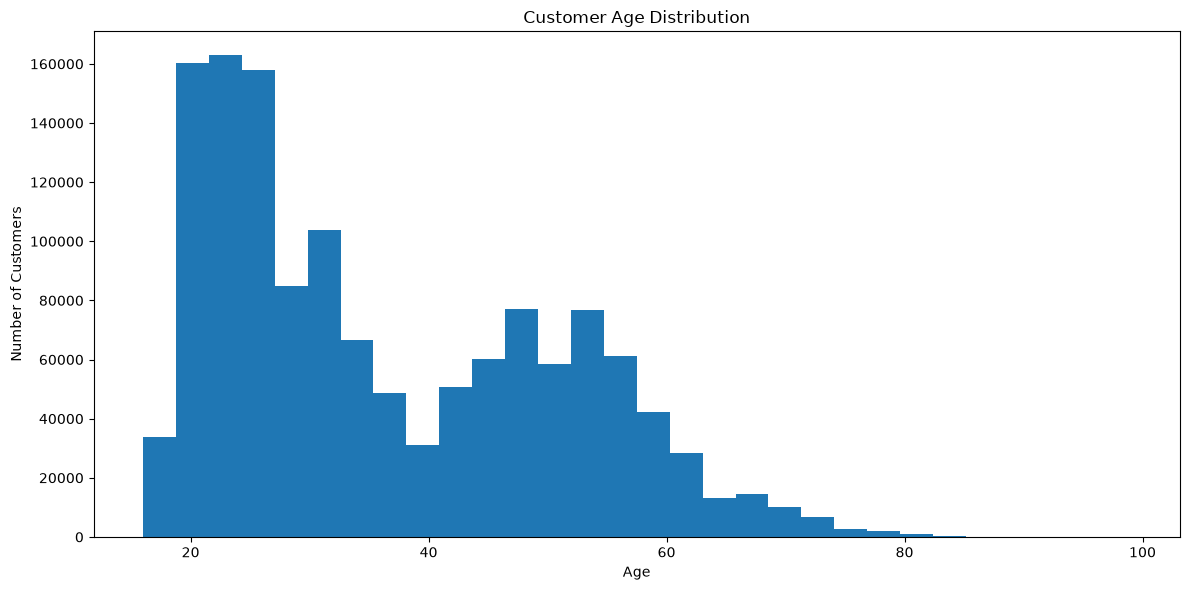

In [19]:
plt.figure(figsize=(12, 6))

plt.hist(
    customers_df["age"].dropna(),
    bins=30
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [20]:
print("Customers below 18:", (customers_df["age"] < 18).sum())
print("Customers above 80:", (customers_df["age"] > 80).sum())

Customers below 18: 9553
Customers above 80: 1112


In [21]:
club_counts = (
    customers_df["club_member_status"]
    .fillna("Missing")
    .value_counts()
)

club_counts

club_member_status
ACTIVE        1272491
PRE-CREATE      92960
Missing          6062
LEFT CLUB         467
Name: count, dtype: int64

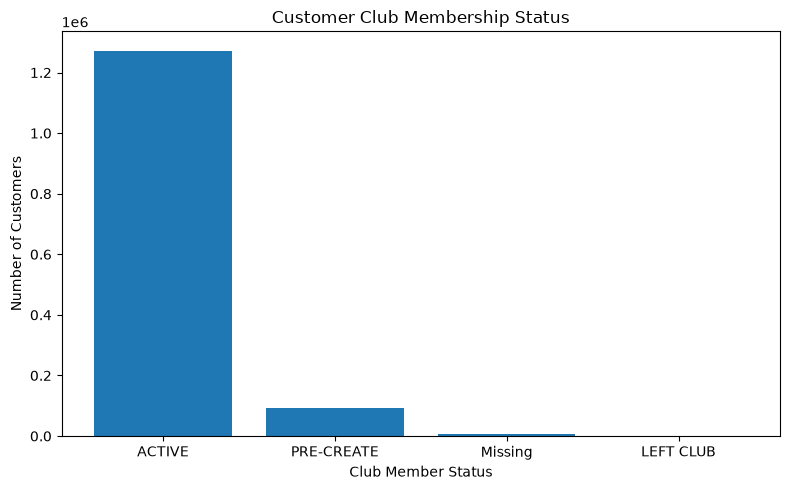

In [22]:
plt.figure(figsize=(8, 5))

plt.bar(
    club_counts.index.astype(str),
    club_counts.values
)

plt.title("Customer Club Membership Status")
plt.xlabel("Club Member Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [23]:
news_counts = (
    customers_df["fashion_news_frequency"]
    .fillna("Missing")
    .value_counts()
)

news_counts

fashion_news_frequency
NONE         877711
Regularly    477416
Missing       16011
Monthly         842
Name: count, dtype: int64

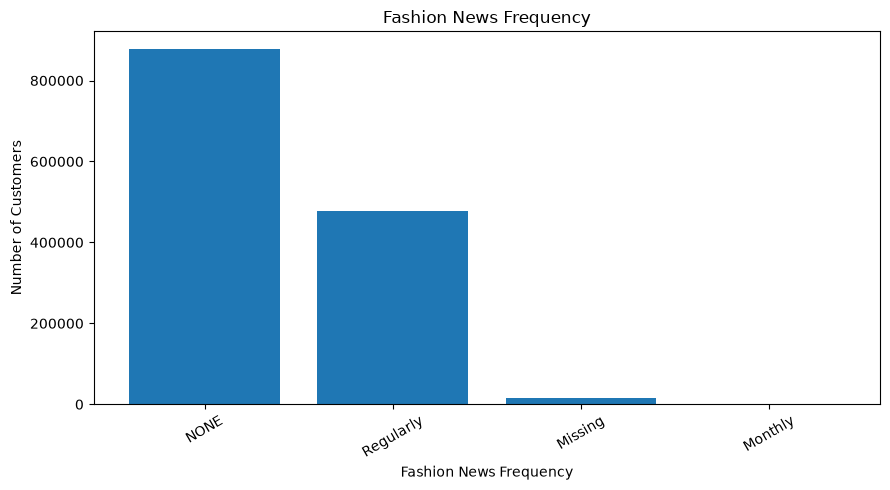

In [24]:
plt.figure(figsize=(9, 5))

plt.bar(
    news_counts.index.astype(str),
    news_counts.values
)

plt.title("Fashion News Frequency")
plt.xlabel("Fashion News Frequency")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [25]:
fn_counts = (
    customers_df["FN"]
    .fillna("Missing")
    .value_counts()
)

active_counts = (
    customers_df["Active"]
    .fillna("Missing")
    .value_counts()
)

print("===== FN =====")
print(fn_counts)

print("\n===== Active =====")
print(active_counts)

===== FN =====
FN
Missing    895050
1.0        476930
Name: count, dtype: int64

===== Active =====
Active
Missing    907576
1.0        464404
Name: count, dtype: int64


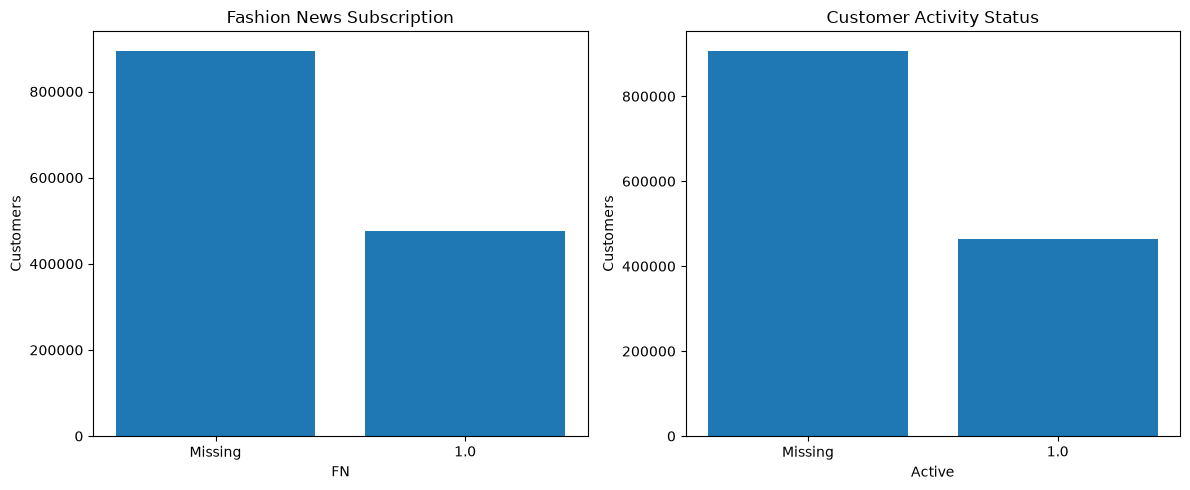

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    fn_counts.index.astype(str),
    fn_counts.values
)
axes[0].set_title("Fashion News Subscription")
axes[0].set_xlabel("FN")
axes[0].set_ylabel("Customers")

axes[1].bar(
    active_counts.index.astype(str),
    active_counts.values
)
axes[1].set_title("Customer Activity Status")
axes[1].set_xlabel("Active")
axes[1].set_ylabel("Customers")

plt.tight_layout()
plt.show()

In [27]:
articles_path = r"C:\Users\SASHANK VARMA K\recommendation-engine-ml-backup\data\raw\articles.csv"

articles_df = pd.read_csv(
    articles_path,
    usecols=[
        "article_id",
        "product_code",
        "prod_name",
        "product_type_name",
        "product_group_name",
        "graphical_appearance_name",
        "colour_group_name",
        "perceived_colour_master_name",
        "department_name",
        "index_name",
        "index_group_name",
        "section_name",
        "garment_group_name",
        "detail_desc"
    ]
)

print("Articles loaded:", articles_df.shape)
articles_df.head()

Articles loaded: (105542, 14)


,article_id,product_code,prod_name,product_type_name,product_group_name,graphical_appearance_name,colour_group_name,perceived_colour_master_name,department_name,index_name,index_group_name,section_name,garment_group_name,detail_desc
0,108775015,108775,Strap top,Vest top,Garment Upper body,Solid,Black,Black,Jersey Basic,Ladieswear,Ladieswear,Womens Everyday Basics,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,Vest top,Garment Upper body,Solid,White,White,Jersey Basic,Ladieswear,Ladieswear,Womens Everyday Basics,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),Vest top,Garment Upper body,Stripe,Off White,White,Jersey Basic,Ladieswear,Ladieswear,Womens Everyday Basics,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),Bra,Underwear,Solid,Black,Black,Clean Lingerie,Lingeries/Tights,Ladieswear,Womens Lingerie,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),Bra,Underwear,Solid,White,White,Clean Lingerie,Lingeries/Tights,Ladieswear,Womens Lingerie,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [28]:
article_missing = (
    articles_df.isna()
    .sum()
    .sort_values(ascending=False)
)

article_missing

detail_desc                     416
article_id                        0
prod_name                         0
product_type_name                 0
product_group_name                0
product_code                      0
graphical_appearance_name         0
colour_group_name                 0
department_name                   0
perceived_colour_master_name      0
index_name                        0
index_group_name                  0
section_name                      0
garment_group_name                0
dtype: int64

In [29]:
article_missing_pct = (
    article_missing / len(articles_df) * 100
).round(2)

article_missing_pct

detail_desc                     0.39
article_id                      0.00
prod_name                       0.00
product_type_name               0.00
product_group_name              0.00
product_code                    0.00
graphical_appearance_name       0.00
colour_group_name               0.00
department_name                 0.00
perceived_colour_master_name    0.00
index_name                      0.00
index_group_name                0.00
section_name                    0.00
garment_group_name              0.00
dtype: float64

In [30]:
product_group_counts = (
    articles_df["product_group_name"]
    .fillna("Missing")
    .value_counts()
)

product_group_counts

product_group_name
Garment Upper body       42741
Garment Lower body       19812
Garment Full body        13292
Accessories              11158
Underwear                 5490
Shoes                     5283
Swimwear                  3127
Socks & Tights            2442
Nightwear                 1899
Unknown                    121
Underwear/nightwear         54
Cosmetic                    49
Bags                        25
Items                       17
Furniture                   13
Garment and Shoe care        9
Stationery                   5
Interior textile             3
Fun                          2
Name: count, dtype: int64

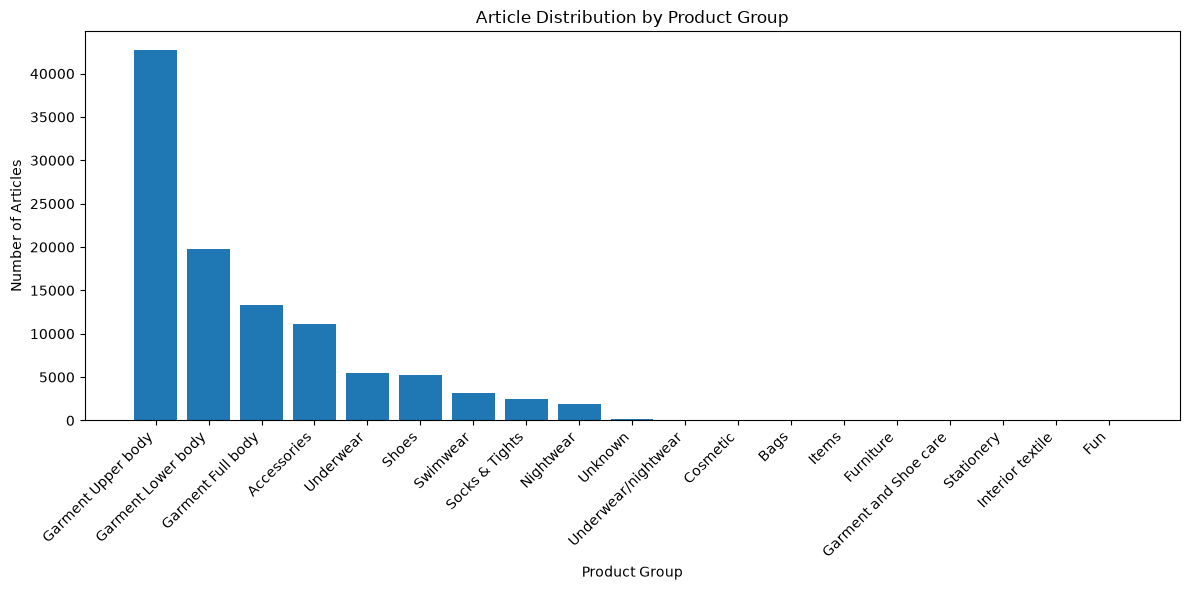

In [31]:
plt.figure(figsize=(12, 6))

plt.bar(
    product_group_counts.index.astype(str),
    product_group_counts.values
)

plt.title("Article Distribution by Product Group")
plt.xlabel("Product Group")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [32]:
product_type_counts = (
    articles_df["product_type_name"]
    .fillna("Missing")
    .value_counts()
    .head(20)
)

product_type_counts

product_type_name
Trousers            11169
Dress               10362
Sweater              9302
T-shirt              7904
Top                  4155
Blouse               3979
Jacket               3940
Shorts               3939
Shirt                3405
Vest top             2991
Underwear bottom     2748
Skirt                2696
Hoodie               2356
Bra                  2212
Socks                1889
Leggings/Tights      1878
Sneakers             1621
Cardigan             1550
Hat/beanie           1349
Garment Set          1320
Name: count, dtype: int64

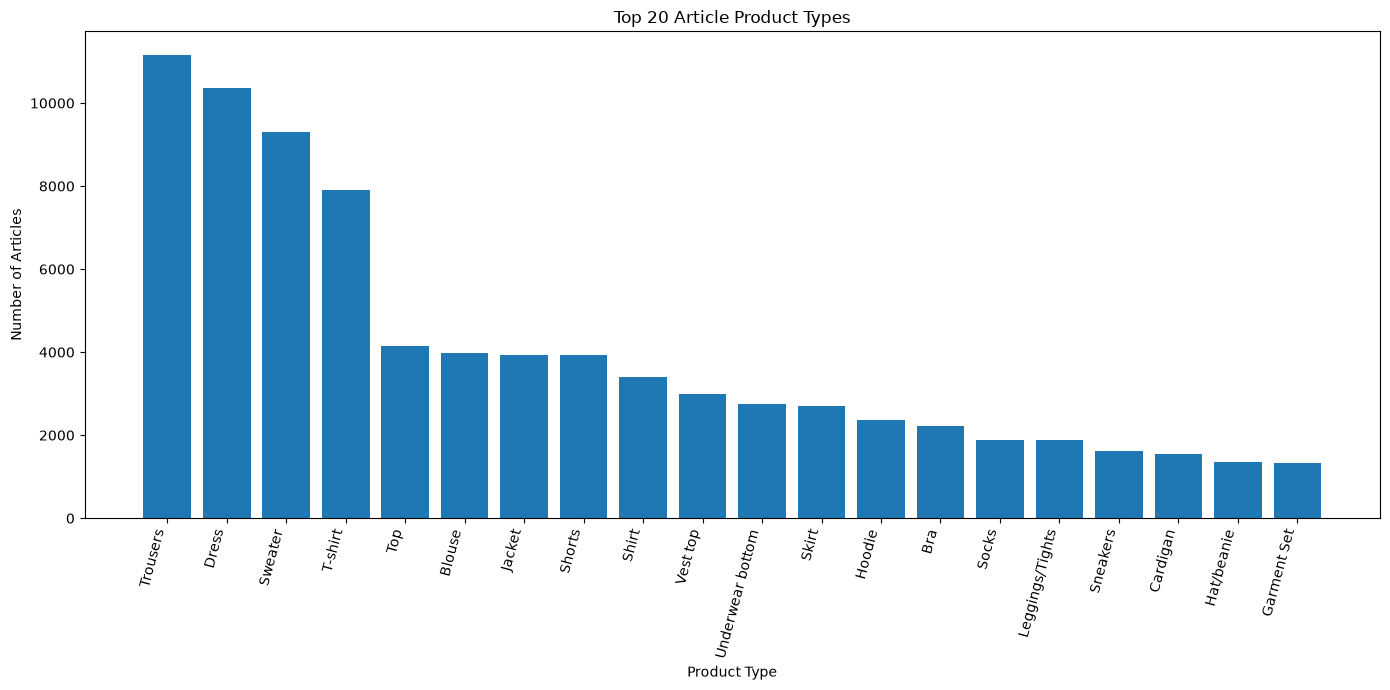

In [33]:
plt.figure(figsize=(14, 7))

plt.bar(
    product_type_counts.index.astype(str),
    product_type_counts.values
)

plt.title("Top 20 Article Product Types")
plt.xlabel("Product Type")
plt.ylabel("Number of Articles")
plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.show()

In [34]:
department_counts = (
    articles_df["department_name"]
    .fillna("Missing")
    .value_counts()
)

print("Number of departments:", len(department_counts))
department_counts.head(20)

Number of departments: 250


department_name
Jersey                     4604
Knitwear                   3503
Trouser                    2655
Blouse                     2362
Dress                      2087
Swimwear                   2075
Kids Girl Jersey Fancy     2032
Expressive Lingerie        1921
Young Girl Jersey Fancy    1874
Jersey Fancy               1754
Jersey Basic               1514
Kids Boy Jersey Fancy      1488
Tops Fancy Jersey          1429
Jersey fancy               1402
Dresses                    1354
Basic 1                    1339
Jewellery                  1163
Shirt                      1153
Baby basics                1147
Tops Knitwear              1115
Name: count, dtype: int64

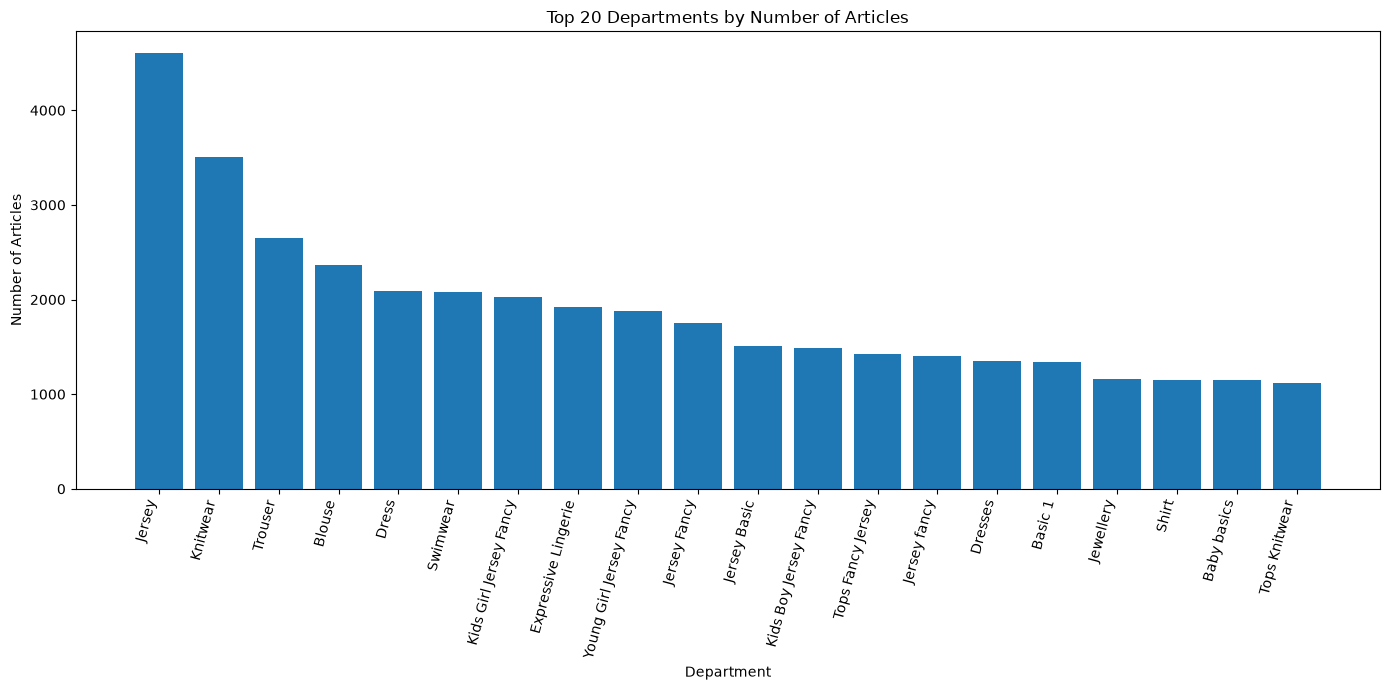

In [35]:
plt.figure(figsize=(14, 7))

top_departments = department_counts.head(20)

plt.bar(
    top_departments.index.astype(str),
    top_departments.values
)

plt.title("Top 20 Departments by Number of Articles")
plt.xlabel("Department")
plt.ylabel("Number of Articles")
plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.show()

In [36]:
colour_counts = (
    articles_df["colour_group_name"]
    .fillna("Missing")
    .value_counts()
)

print("Number of colour groups:", len(colour_counts))
colour_counts.head(15)

Number of colour groups: 50


colour_group_name
Black             22670
Dark Blue         12171
White              9542
Light Pink         5811
Grey               4487
Light Beige        3356
Blue               3308
Red                3056
Light Blue         3012
Greenish Khaki     2767
Dark Grey          2731
Off White          2726
Beige              2712
Dark Red           2340
Dark Green         2106
Name: count, dtype: int64

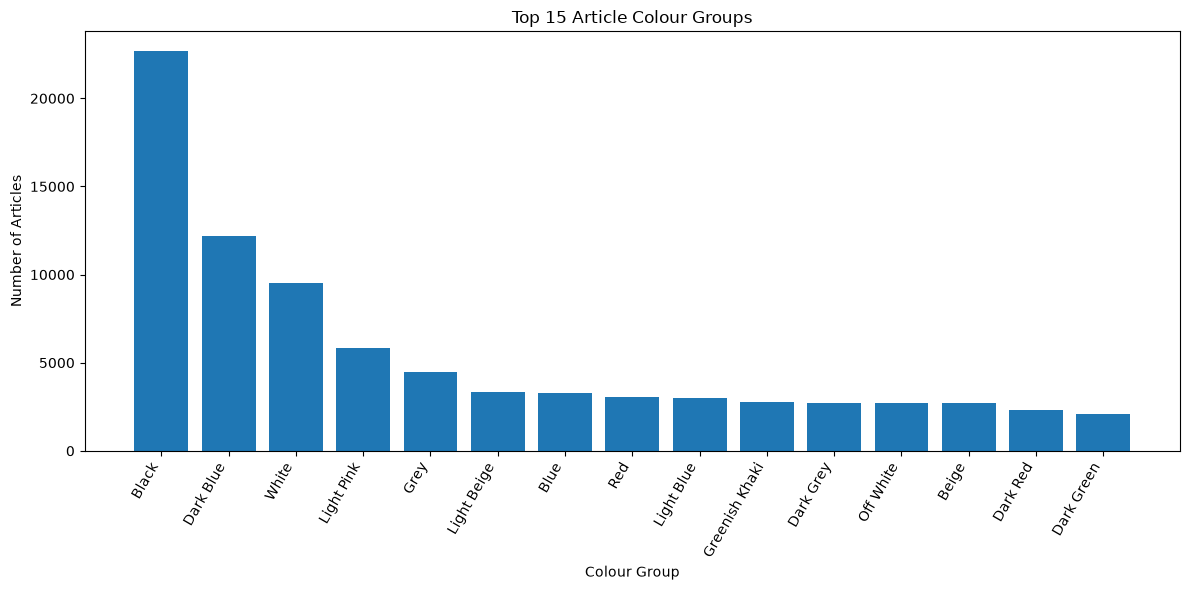

In [37]:
top_colours = colour_counts.head(15)

plt.figure(figsize=(12, 6))

plt.bar(
    top_colours.index.astype(str),
    top_colours.values
)

plt.title("Top 15 Article Colour Groups")
plt.xlabel("Colour Group")
plt.ylabel("Number of Articles")
plt.xticks(rotation=60, ha="right")

plt.tight_layout()
plt.show()

In [38]:
index_group_counts = (
    articles_df["index_group_name"]
    .fillna("Missing")
    .value_counts()
)

index_group_counts

index_group_name
Ladieswear       39737
Baby/Children    34711
Divided          15149
Menswear         12553
Sport             3392
Name: count, dtype: int64

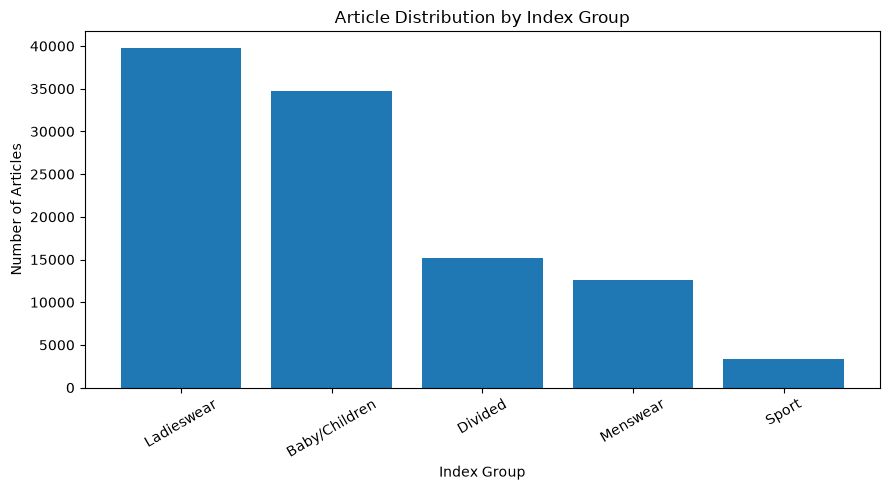

In [39]:
plt.figure(figsize=(9, 5))

plt.bar(
    index_group_counts.index.astype(str),
    index_group_counts.values
)

plt.title("Article Distribution by Index Group")
plt.xlabel("Index Group")
plt.ylabel("Number of Articles")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [40]:
import os

processed_dir = "../data/processed"

print("Processed directory:")
print(os.listdir(processed_dir))

Processed directory:
['.gitkeep', 'eda', 'enriched_item_features.csv', 'enriched_user_features.csv', 'item_features.csv', 'train_interactions.csv', 'user_features.csv', 'validation_interactions.csv']


In [41]:
for root, dirs, files in os.walk("../data/processed"):
    for file in files:
        if "interaction" in file.lower():
            print(os.path.join(root, file))

../data/processed\train_interactions.csv
../data/processed\validation_interactions.csv
../data/processed\eda\interaction_article_stats.csv
../data/processed\eda\interaction_customer_stats.csv
../data/processed\eda\interaction_overview.csv
../data/processed\eda\interaction_sparsity.csv
../data/processed\eda\repeat_interaction_summary.csv


In [42]:
customer_purchase_counts = top_customers_df["count"]

print("===== CUSTOMER PURCHASE DISTRIBUTION =====")

print(f"Maximum purchases: {customer_purchase_counts.max():,}")
print(f"Minimum in top 20: {customer_purchase_counts.min():,}")
print(f"Average in top 20: {customer_purchase_counts.mean():,.2f}")
print(f"Median in top 20: {customer_purchase_counts.median():,.2f}")

===== CUSTOMER PURCHASE DISTRIBUTION =====
Maximum purchases: 1,895
Minimum in top 20: 1,009
Average in top 20: 1,188.00
Median in top 20: 1,130.00


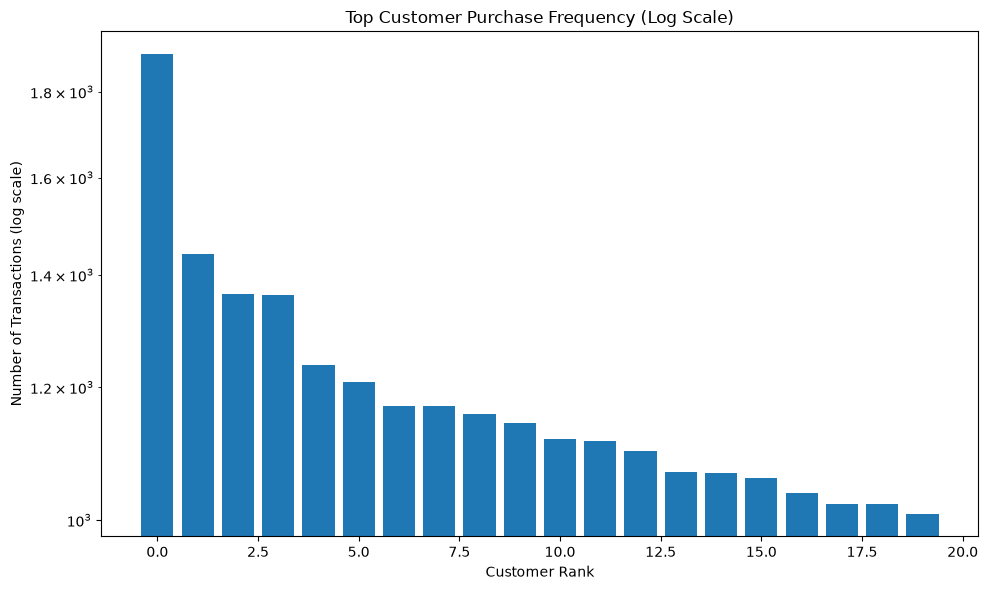

In [43]:
plt.figure(figsize=(10, 6))

plt.bar(
    range(len(customer_purchase_counts)),
    customer_purchase_counts
)

plt.yscale("log")

plt.title("Top Customer Purchase Frequency (Log Scale)")
plt.xlabel("Customer Rank")
plt.ylabel("Number of Transactions (log scale)")

plt.tight_layout()
plt.show()

In [44]:
article_purchase_counts = top_articles_df["count"]

print("===== ARTICLE POPULARITY =====")

print(f"Maximum purchases: {article_purchase_counts.max():,}")
print(f"Minimum in top 20: {article_purchase_counts.min():,}")
print(f"Average in top 20: {article_purchase_counts.mean():,.2f}")
print(f"Median in top 20: {article_purchase_counts.median():,.2f}")

===== ARTICLE POPULARITY =====
Maximum purchases: 50,287
Minimum in top 20: 19,143
Average in top 20: 24,523.75
Median in top 20: 21,152.00


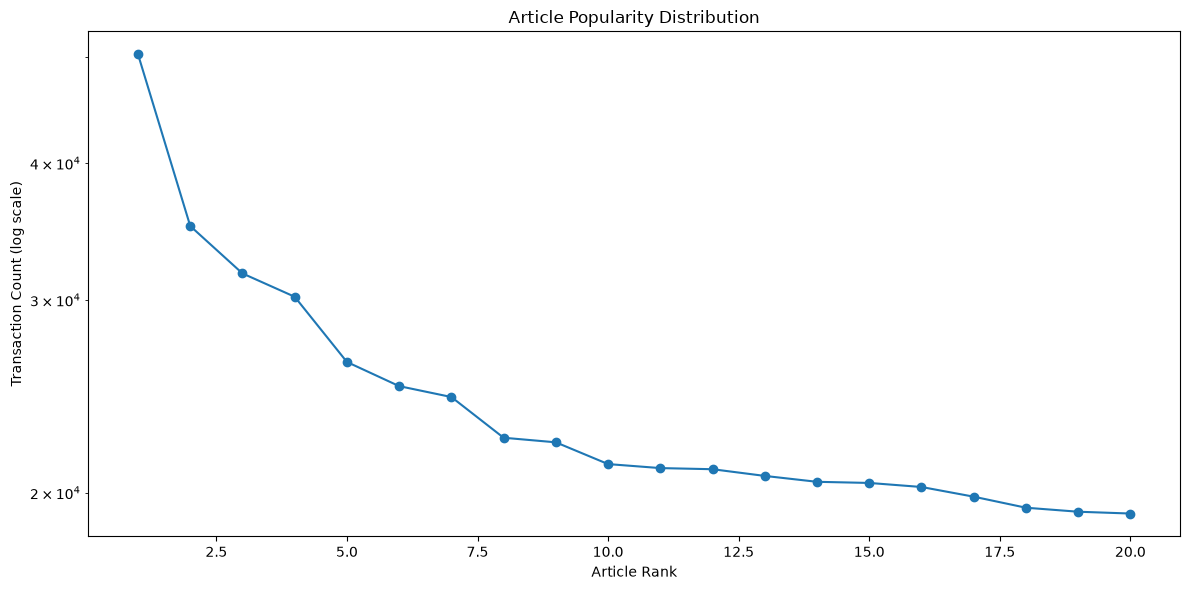

In [45]:
sorted_article_counts = (
    top_articles_df["count"]
    .sort_values(ascending=False)
    .reset_index(drop=True)
)

plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(sorted_article_counts) + 1),
    sorted_article_counts,
    marker="o"
)

plt.yscale("log")

plt.title("Article Popularity Distribution")
plt.xlabel("Article Rank")
plt.ylabel("Transaction Count (log scale)")

plt.tight_layout()
plt.show()

In [46]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total transactions",
        "Unique customers",
        "Unique articles",
        "Training interactions",
        "Validation interactions",
        "Training customers",
        "Training articles",
        "Validation customers",
        "Validation articles"
    ],
    "Value": [
        int(overview.loc[0, "transaction_count"]),
        int(overview.loc[0, "unique_customers"]),
        int(overview.loc[0, "unique_articles"]),
        2_002_124,
        300_304,
        687_245,
        79_407,
        153_790,
        21_496
    ]
})

eda_summary

,Metric,Value
0,Total transactions,31788324
1,Unique customers,1362281
2,Unique articles,104547
3,Training interactions,2002124
4,Validation interactions,300304
5,Training customers,687245
6,Training articles,79407
7,Validation customers,153790
8,Validation articles,21496


In [47]:
interaction_overview = pd.read_csv(
    "../data/processed/eda/interaction_overview.csv"
)

customer_stats = pd.read_csv(
    "../data/processed/eda/interaction_customer_stats.csv"
)

article_stats = pd.read_csv(
    "../data/processed/eda/interaction_article_stats.csv"
)

sparsity_df = pd.read_csv(
    "../data/processed/eda/interaction_sparsity.csv"
)

popularity_df = pd.read_csv(
    "../data/processed/eda/article_popularity_summary.csv"
)

repeat_df = pd.read_csv(
    "../data/processed/eda/repeat_interaction_summary.csv"
)

print("Interaction EDA results loaded successfully.")

Interaction EDA results loaded successfully.


In [48]:
print("===== CUSTOMER-ITEM INTERACTION SPARSITY =====")

print(
    f"Unique customers: "
    f"{sparsity_df.loc[0, 'unique_customers']:,}"
)

print(
    f"Unique articles: "
    f"{sparsity_df.loc[0, 'unique_articles']:,}"
)

print(
    f"Observed customer-item pairs: "
    f"{sparsity_df.loc[0, 'unique_customer_article_pairs']:,}"
)

print(
    f"Possible customer-item pairs: "
    f"{sparsity_df.loc[0, 'possible_customer_article_pairs']:,}"
)

print(
    f"Interaction density: "
    f"{sparsity_df.loc[0, 'interaction_density_percent']:.6f}%"
)

print(
    f"Interaction sparsity: "
    f"{sparsity_df.loc[0, 'interaction_sparsity_percent']:.6f}%"
)

===== CUSTOMER-ITEM INTERACTION SPARSITY =====
Unique customers: 1,362,281
Unique articles: 104,547
Observed customer-item pairs: 27,306,439
Possible customer-item pairs: 142,422,391,707
Interaction density: 0.019173%
Interaction sparsity: 99.980827%


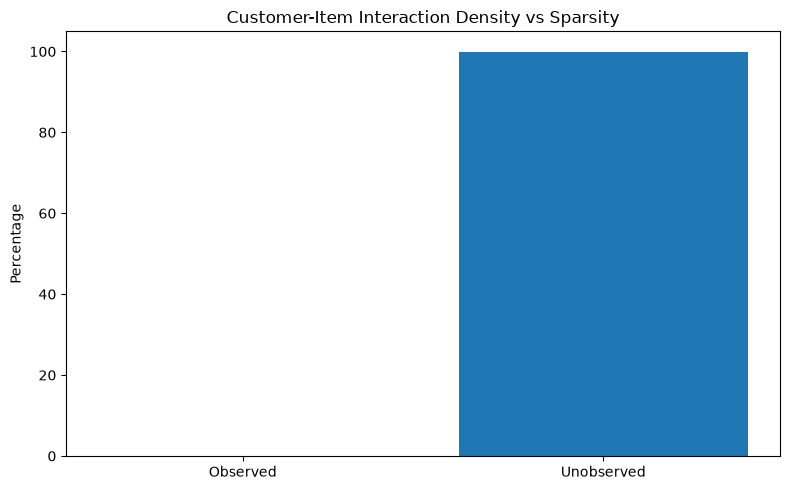

In [49]:
density = sparsity_df.loc[
    0, "interaction_density_percent"
]

sparsity = sparsity_df.loc[
    0, "interaction_sparsity_percent"
]

plt.figure(figsize=(8, 5))

plt.bar(
    ["Observed", "Unobserved"],
    [density, sparsity]
)

plt.title("Customer-Item Interaction Density vs Sparsity")
plt.ylabel("Percentage")

plt.tight_layout()
plt.show()

In [50]:
print("===== ARTICLE LONG-TAIL ANALYSIS =====")

total_articles = popularity_df.loc[0, "total_articles"]
one_interaction = popularity_df.loc[0, "articles_with_1_interaction"]
five_or_less = popularity_df.loc[0, "articles_with_1_to_5_interactions"]
ten_or_less = popularity_df.loc[0, "articles_with_1_to_10_interactions"]
fifty_or_less = popularity_df.loc[0, "articles_with_1_to_50_interactions"]

print(f"Total articles: {total_articles:,}")
print(f"Articles with exactly 1 interaction: {one_interaction:,}")
print(f"Articles with <= 5 interactions: {five_or_less:,}")
print(f"Articles with <= 10 interactions: {ten_or_less:,}")
print(f"Articles with <= 50 interactions: {fifty_or_less:,}")

print()
print(f"<= 5 interactions: "
      f"{five_or_less / total_articles * 100:.2f}%")

print(f"<= 10 interactions: "
      f"{ten_or_less / total_articles * 100:.2f}%")

print(f"<= 50 interactions: "
      f"{fifty_or_less / total_articles * 100:.2f}%")

===== ARTICLE LONG-TAIL ANALYSIS =====
Total articles: 104,547
Articles with exactly 1 interaction: 4,491
Articles with <= 5 interactions: 14,669
Articles with <= 10 interactions: 22,477
Articles with <= 50 interactions: 47,851

<= 5 interactions: 14.03%
<= 10 interactions: 21.50%
<= 50 interactions: 45.77%


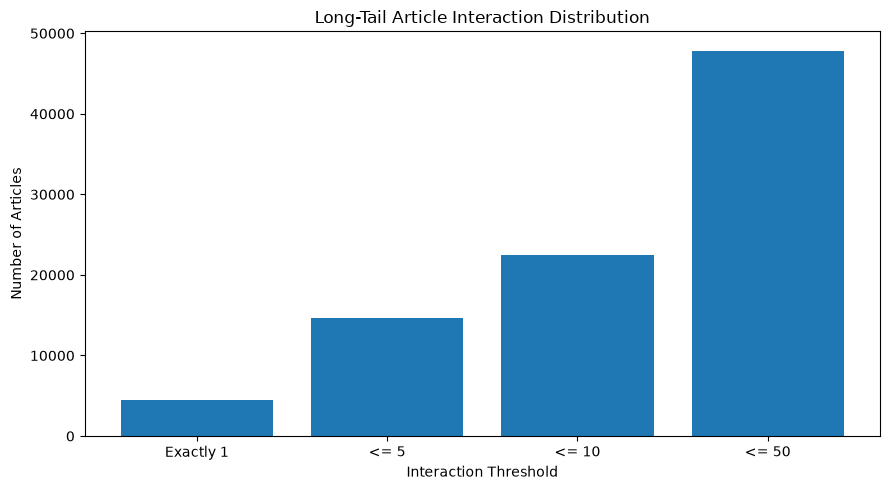

In [51]:
long_tail_labels = [
    "Exactly 1",
    "<= 5",
    "<= 10",
    "<= 50"
]

long_tail_values = [
    one_interaction,
    five_or_less,
    ten_or_less,
    fifty_or_less
]

plt.figure(figsize=(9, 5))

plt.bar(
    long_tail_labels,
    long_tail_values
)

plt.title("Long-Tail Article Interaction Distribution")
plt.xlabel("Interaction Threshold")
plt.ylabel("Number of Articles")

plt.tight_layout()
plt.show()

In [52]:
cold_start_df = pd.read_csv(
    "../data/processed/eda/cold_start_summary.csv"
)

print("Cold-start analysis loaded successfully.")

Cold-start analysis loaded successfully.


In [53]:
print("===== COLD-START SUMMARY =====")

print(
    f"Validation users: "
    f"{cold_start_df.loc[0, 'validation_users']:,}"
)

print(
    f"Cold-start users: "
    f"{cold_start_df.loc[0, 'cold_start_users']:,}"
)

print(
    f"Cold-start user rate: "
    f"{cold_start_df.loc[0, 'cold_start_user_percentage']:.2f}%"
)

print()

print(
    f"Validation articles: "
    f"{cold_start_df.loc[0, 'validation_articles']:,}"
)

print(
    f"Cold-start articles: "
    f"{cold_start_df.loc[0, 'cold_start_articles']:,}"
)

print(
    f"Cold-start article rate: "
    f"{cold_start_df.loc[0, 'cold_start_article_percentage']:.2f}%"
)

===== COLD-START SUMMARY =====
Validation users: 245,945
Cold-start users: 24,252
Cold-start user rate: 9.86%

Validation articles: 28,889
Cold-start articles: 3,790
Cold-start article rate: 13.12%
